# 06 · Placar das três configurações, interpretação e erros reais

Roda **A · sem contexto**, **B · RAG simples** e **C · agente** nos mesmos casos, com `temperature=0` e `seed=7` (reprodutível). Os resultados são gravados em `avaliacao/resultados/`.

**Execute com o Ollama real.** Com o backend `stub` os resultados vão para uma pasta temporária e **não valem**.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
from rotalivre_ai import config, kb, metrics, montar, pipelines
from rotalivre_ai.runner import checar_ollama, rodar_todas
print(checar_ollama())

Ollama OK em http://localhost:11434 | LLM=qwen2.5:7b | embeddings=bge-m3


In [2]:
trechos, be, idx = montar()
casos = kb.carregar_casos()
df, respostas = rodar_todas(casos, idx, be, trechos)
placar = metrics.resumir(df)
placar

A_sem_contexto 34/34
B_rag_simples 34/34
C_agente 34/34


,configuração,acerto (%),alucinação (%),JSON válido (%),citação correta (%),recusa correta em 'não consta' (%),recusa indevida em 'consta' (%),casos
0,A_sem_contexto,17.6,52.9,100.0,23.5,25.0,11.5,34
1,B_rag_simples,94.1,0.0,100.0,91.2,100.0,3.8,34
2,C_agente,76.5,0.0,100.0,76.5,100.0,30.8,34


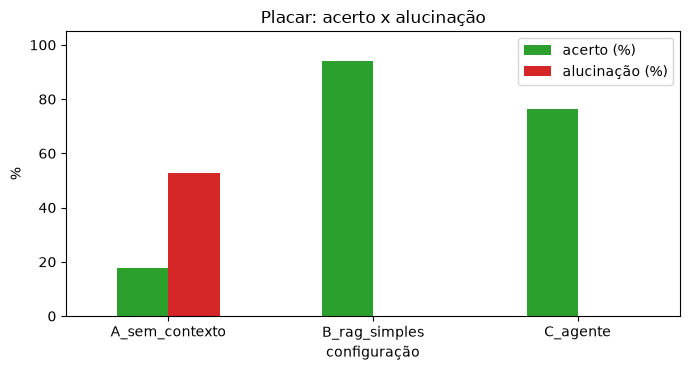

In [3]:
df.to_csv(config.RESULTS_DIR / "avaliacao_por_caso.csv", index=False)
(config.RESULTS_DIR / "respostas.json").write_text(json.dumps(respostas, ensure_ascii=False, indent=1), encoding="utf-8")
placar.to_csv(config.RESULTS_DIR / "placar.csv", index=False)
(config.RESULTS_DIR / "placar.md").write_text(
    f"Modelo: `{config.LLM_MODEL}` | embeddings: `{config.EMB_MODEL}` | limiar: {config.limiar():.3f} | casos: {len(casos)}\n\n" + placar.to_markdown(index=False) + "\n", encoding="utf-8")
ax = placar.set_index("configuração")[["acerto (%)", "alucinação (%)"]].plot.bar(rot=0, figsize=(7, 3.8), ylim=(0, 105), color=["tab:green", "tab:red"])
ax.set_title("Placar: acerto x alucinação"); ax.set_ylabel("%"); plt.tight_layout()
plt.savefig(config.RESULTS_DIR / "placar.png", dpi=130); plt.show()

## Resultados interpretados
O texto abaixo é **gerado dos números acima** (nada escrito à mão). Use-o como base para a seção de conclusão do README.

In [4]:
def v(cfg, col): return float(placar.set_index("configuração").loc[cfg, col])
A, B, C = "A_sem_contexto", "B_rag_simples", "C_agente"
RC = "recusa correta em 'não consta' (%)"
RI = "recusa indevida em 'consta' (%)"
print(f"* Acerto: A {v(A,'acerto (%)'):.0f}% → B {v(B,'acerto (%)'):.0f}% → C {v(C,'acerto (%)'):.0f}%.")
print(f"* Alucinação: A {v(A,'alucinação (%)'):.0f}% → B {v(B,'alucinação (%)'):.0f}% → C {v(C,'alucinação (%)'):.0f}%.")
print(f"* Recusa correta quando 'não consta': A {v(A,RC):.0f}%, B {v(B,RC):.0f}%, C {v(C,RC):.0f}%.")
print(f"* Custo da cautela (recusa indevida em 'consta'): B {v(B,RI):.0f}%, C {v(C,RI):.0f}%.")
print(f"* Citação correta: A {v(A,'citação correta (%)'):.0f}% (não tem fonte), B {v(B,'citação correta (%)'):.0f}%, C {v(C,'citação correta (%)'):.0f}%.")
print(f"* Nº de casos: {int(placar['casos'].iloc[0])} por configuração; com tão poucos casos, diferenças pequenas não são estatisticamente significativas.")

* Acerto: A 18% → B 94% → C 76%.
* Alucinação: A 53% → B 0% → C 0%.
* Recusa correta quando 'não consta': A 25%, B 100%, C 100%.
* Custo da cautela (recusa indevida em 'consta'): B 4%, C 31%.
* Citação correta: A 24% (não tem fonte), B 91%, C 76%.
* Nº de casos: 34 por configuração; com tão poucos casos, diferenças pequenas não são estatisticamente significativas.


## Erros reais (para o item 'Os 5 erros, a causa e a correção proposta')
A tabela lista os erros **que realmente ocorreram** nesta execução. Escolha **5** (de preferência de tipos diferentes e de configurações diferentes), investigue a **causa** (olhe o `trace` em `respostas.json`, o trecho recuperado e o JSON bruto) e escreva a **correção proposta** no README. Não invente causas: confirme olhando os dados.

In [5]:
erros = df[df.erro != ""][["config", "id", "tipo", "pergunta", "resposta", "trecho_ids", "erro"]].sort_values(["config", "erro"])
print(f"{len(erros)} erros no total"); print(erros.groupby(["config", "erro"]).size().to_string())
erros

38 erros no total
config          erro                                             
A_sem_contexto  alucinação: número fora da base ['0.85']             1
                alucinação: número fora da base ['0.90']             1
                alucinação: número fora da base ['1']                2
                alucinação: número fora da base ['1.5']              1
                alucinação: número fora da base ['1.50']             1
                alucinação: número fora da base ['10']               1
                alucinação: número fora da base ['13.285']           1
                alucinação: número fora da base ['2.00']             1
                alucinação: número fora da base ['2.50']             1
                alucinação: número fora da base ['229']              1
                alucinação: número fora da base ['500', '800']       1
                alucinação: respondeu algo que não consta na base    6
                recusa indevida (a base tinha a resposta)       

,config,id,tipo,pergunta,resposta,trecho_ids,erro
13,A_sem_contexto,C14,consta,Qual a altura livre mínima para obstáculos verticais na calçada?,"A altura livre mínima para obstáculos verticais na calçada, de acordo com a ABNT NBR 9050, é de 0,85 metros.",[],alucinação: número fora da base ['0.85']
8,A_sem_contexto,C09,consta,Qual a largura mínima da rampa de rebaixamento da guia?,"A largura mínima da rampa de rebaixamento da guia deve ser de 0,90 metros conforme a ABNT NBR 9050.",[],alucinação: número fora da base ['0.90']
2,A_sem_contexto,C03,consta,Qual a inclinação transversal máxima da faixa livre?,"A inclinação transversal máxima da faixa livre deve ser de até 1:20, conforme estabelecido na NBR 9050.",[],alucinação: número fora da base ['1']
9,A_sem_contexto,C10,consta,Qual a inclinação máxima da rampa de rebaixamento da guia?,"A inclinação máxima da rampa de rebaixamento da guia deve ser de no máximo 1:20, conforme estabelecido na NBR 9050.",[],alucinação: número fora da base ['1']
3,A_sem_contexto,C04,consta,Qual a largura mínima recomendada para a faixa de serviço da calçada?,"A largura mínima recomendada para a faixa de serviço da calçada no Brasil é de 1,5 metro, conforme estabelecido na NBR 9050.",[],alucinação: número fora da base ['1.5']
0,A_sem_contexto,C01,consta,Qual a largura mínima da faixa livre da calçada segundo a NBR 9050?,"A largura mínima da faixa livre da calçada, de acordo com a NBR 9050, é de 1,50 metro.",[],alucinação: número fora da base ['1.50']
24,A_sem_contexto,C25,consta,A que distância o robô aciona o freio de emergência?,"O robô aciona o freio de emergência a uma distância pré-definida, geralmente entre 5 a 10 centímetros de obstáculos perigosos, para evit...",[],alucinação: número fora da base ['10']
15,A_sem_contexto,C16,consta,Qual norma trata da sinalização tátil no piso das calçadas?,"A norma que trata da sinalização tátil no piso das calçadas no Brasil é a NBR 13.285, que estabelece os requisitos para a acessibilidade...",[],alucinação: número fora da base ['13.285']
1,A_sem_contexto,C02,consta,Qual a altura livre mínima da faixa livre da calçada?,"A altura livre mínima da faixa livre da calçada, conforme estabelecido na NBR 9050, é de 2,00 metros.",[],alucinação: número fora da base ['2.00']
12,A_sem_contexto,C13,consta,Qual a altura mínima de toldos e marquises sobre a calçada?,"A altura mínima recomendada para toldos e marquises sobre a calçada é de 2,50 metros, conforme estabelecido na NBR 9050 - Projeto de Edi...",[],alucinação: número fora da base ['2.50']


In [6]:
linhas = ["| Config | Caso | Tipo de erro | Pergunta | Resposta dada |", "| --- | --- | --- | --- | --- |"]
for _, e in erros.iterrows():
    linhas.append(f"| {e.config} | {e.id} | {e.erro} | {e.pergunta} | {str(e.resposta)[:160].replace('|', '/')} |")
(config.RESULTS_DIR / "erros_candidatos.md").write_text("\n".join(linhas) + "\n", encoding="utf-8")
print("gravado em", config.RESULTS_DIR / "erros_candidatos.md")

gravado em C:\Users\Brunin\OneDrive\Documentos\gs-ia-26\avaliacao\resultados\erros_candidatos.md
